# ID vs Mech: soma and reconstruction statistics

Compares the cultures imaged with the **ID** stain (DAPI, MAP2, F-actin, Ki67) and the **Mech** stain (DAPI, MAP2, Piezo1, Tuj1).
Every image folder in `data/` processed by the pipeline is picked up automatically (group from the file name: `_ID_` or `_Mech_`):

1. `Image_Processor.py` → `auto_cells.npy` (DAPI nuclei classified with MAP2 / F-actin / Ki67), `somas_data.npy` (accepted neuron somas),
   `astrocytes_data.npy` (accepted astrocytes)
2. `segment_neurons.py --sigma 2` → `neuron_segmentation<tag>.tiff`, `neuron_labels<tag>.tiff`
3. `NeuronSkeletonizer.py --tag <tag>` → `morphologies<tag>/*.swc`

Images missing a step are listed and skipped for that part. Per-image numbers are cached in `results/presentation/cache/`
(delete a file there after re-running the pipeline on that image). Figures and tables go to `results/presentation/`.

**Caveats for the comparison**
- Astrocytes and Ki67+ cells can only be measured with the ID stain (Mech has no F-actin / Ki67 channel): they are *not measured* for Mech, not zero.
- Mech is segmented on MAP2 **+ Tuj1** (Tuj1 adds axons and thin neurites), ID on MAP2 only: reconstruction differences are partly due to the stain.
- Statistics between groups use **one value per image** (images are the replicates; neurons of one image are not independent).
  With fewer than 3 images per group no test is run.

In [1]:
import os, glob, json, re
import numpy as np
import pandas as pd
import tifffile as tiff
from scipy import ndimage, stats
import matplotlib.pyplot as plt

DATA = 'data'
OUT = 'results/presentation'
ZFILL = False          # True: use the outputs segmented with --fill-z-support 0.5 (tag _zfill0.5) when present
SHOLL_STEP_UM = 5.0
SHOLL_MAX_UM = 120.0
FAR_FROM_SOMA_UM = 10.0  # neuron volume farther than this from the soma centre = "neurite volume"
GROUPS = {'ID': '#1b9e77', 'Mech': '#d95f02'}   # colour per group, used in every figure
os.makedirs(os.path.join(OUT, 'cache'), exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.labelsize': 10})

In [2]:
def group_of(name):
    if re.search('_mech_', name, re.I):
        return 'Mech'
    if re.search('_id_', name, re.I):
        return 'ID'
    return None

def tag_of(folder, names):
    """Output tag of segment_neurons.py --sigma 2 for this image (Tuj1 added for Mech stains)."""
    tag = '_sigma2' + ('_zfill0.5' if ZFILL else '') + ('_map2-tuj1' if 'tuj1' in names else '')
    return tag if os.path.exists(os.path.join(folder, f'neuron_labels{tag}.tiff')) else None

images = []
for folder in sorted(glob.glob(os.path.join(DATA, '*', 'processed_metadata.npy'))):
    folder = os.path.dirname(folder)
    name = os.path.basename(folder)
    grp = group_of(name)
    if grp is None:
        continue
    meta = np.load(os.path.join(folder, 'processed_metadata.npy'), allow_pickle=True).item()
    names = meta.get('channel_names') or []
    tag = tag_of(folder, names)
    images.append({'image': name, 'group': grp, 'folder': folder, 'tag': tag, 'channels': names, 'xy_res': meta['xy_res'],
                   'z_res': meta['z_res'], 'shape_zyx': (meta['z_px'], meta['height_px'], meta['width_px']),
                   'has_cells': os.path.exists(os.path.join(folder, 'auto_cells.npy')),
                   'has_swc': tag is not None and os.path.isdir(os.path.join(folder, f'morphologies{tag}'))})
pd.DataFrame(images)[['image', 'group', 'tag', 'has_cells', 'has_swc', 'channels']]

,image,group,tag,has_cells,has_swc,channels
0,IF_D14_ID_40x_3petri_middle_Ch2_,ID,_sigma2,True,True,"[dapi, map2, actin, ki67, ch5]"
1,IF_D14_Mech_40x_up_Ch1_003,Mech,_sigma2_map2-tuj1,True,True,"[dapi, map2, piezo1, tuj1, ch5]"


## Per-image statistics (cached)

In [3]:
def soma_stats(im):
    """Cell proposals (auto_cells.npy: class 0 neuron / 1 astrocyte / 2 other, Ki67+ flag) and accepted cells."""
    f = im['folder']
    area_mm2 = im['shape_zyx'][1] * im['shape_zyx'][2] * im['xy_res'] ** 2 / 1e6
    has_ki67, has_actin = 'ki67' in im['channels'], 'actin' in im['channels']
    s = {'area_mm2': area_mm2, 'ki67_measured': has_ki67, 'astro_measured': has_actin}
    if im['has_cells']:
        c = np.load(os.path.join(f, 'auto_cells.npy'))
        cls, ki = c[:, 4].astype(int), c[:, 5] > 0
        s.update(nuclei=len(c), prop_neurons=int(((cls == 0) & ~ki).sum()),
                 prop_astrocytes=int(((cls == 1) & ~ki).sum()) if has_actin else np.nan,
                 ki67_pos=int(ki.sum()) if has_ki67 else np.nan, others=int(((cls == 2) & ~ki).sum()))
    s['accepted_neurons'] = len(np.load(os.path.join(f, 'somas_data.npy'))) if os.path.exists(os.path.join(f, 'somas_data.npy')) else np.nan
    a = os.path.join(f, 'astrocytes_data.npy')
    s['accepted_astrocytes'] = len(np.load(a)) if os.path.exists(a) else (0 if has_actin else np.nan)
    return s


def read_swc(path):
    a = np.loadtxt(path, comments='#', ndmin=2)
    return a[:, 2:5], a[:, 5], a[:, 6].astype(int) - 1   # xyz um, radius um, parent index (-1 root... -2 after shift)


def swc_stats(path):
    xyz, rad, par = read_swc(path)
    par = np.where(par < 0, -1, par)
    n = len(par)
    nchild = np.bincount(par[1:], minlength=n)
    seg = np.r_[0, np.linalg.norm(xyz[1:] - xyz[par[1:]], axis=1)]
    soma_r = rad[0]
    seg[1:][par[1:] == 0] = np.maximum(0, seg[1:][par[1:] == 0] - soma_r)   # stems start at the soma surface
    # path length from the soma and branch (section) lengths between branch points / tips
    path = np.zeros(n)
    for i in range(1, n):
        path[i] = path[par[i]] + seg[i]
    ends = np.flatnonzero((nchild != 1) & (np.arange(n) > 0))           # branch points and tips end a section
    sections = []
    for e in ends:
        L, v = 0.0, e
        while v > 0:
            L += seg[v]; v = par[v]
            if v == 0 or nchild[v] > 1:
                break
        sections.append(L)
    d = np.linalg.norm(xyz - xyz[0], axis=1)
    radii = np.arange(SHOLL_STEP_UM, SHOLL_MAX_UM + 1e-9, SHOLL_STEP_UM)
    dc, dp = d[1:], d[par[1:]]
    sholl = [int(((np.minimum(dc, dp) < r) & (np.maximum(dc, dp) >= r)).sum()) for r in radii]
    return {'length_um': float(seg.sum()), 'stems': int(nchild[0]), 'branch_points': int((nchild[1:] > 1).sum()),
            'tips': int((nchild[1:] == 0).sum()), 'max_reach_um': float(d.max()), 'max_path_um': float(path.max()),
            'mean_section_um': float(np.mean(sections)) if sections else 0.0, 'soma_radius_um': float(soma_r),
            'mean_neurite_radius_um': float(rad[1:].mean()) if n > 1 else np.nan, 'sholl': sholl}


def recon_stats(im):
    """Per-image segmentation numbers and per-neuron volumes (labels) + SWC statistics."""
    f, tag = im['folder'], im['tag']
    vox = im['xy_res'] ** 2 * im['z_res']
    seg = tiff.imread(os.path.join(f, f'neuron_segmentation{tag}.tiff')) > 0
    lab = tiff.imread(os.path.join(f, f'neuron_labels{tag}.tiff'))
    labelled = lab > 0
    img = {'seg_fraction': float(seg.mean()), 'seg_volume_um3': float(seg.sum() * vox),
           'unassigned_fraction': float((seg & ~labelled).sum() / seg.sum()),
           'labelled_outside_seg_um3': float((labelled & ~seg).sum() * vox), 'n_labels': int(len(np.unique(lab)) - 1)}
    neurons = []
    for k, sl in enumerate(ndimage.find_objects(lab), start=1):
        if sl is None:
            continue
        m = lab[sl] == k
        zz, yy, xx = np.nonzero(m)
        pos = np.c_[(zz + sl[0].start) * im['z_res'], (yy + sl[1].start) * im['xy_res'], (xx + sl[2].start) * im['xy_res']]
        row = {'label': k, 'volume_um3': float(m.sum() * vox), 'z_extent_um': float((np.ptp(zz) + 1) * im['z_res'])}
        swc = os.path.join(f, f'morphologies{tag}', f'neuron_{k}.swc')
        if os.path.exists(swc):
            st = swc_stats(swc)
            soma_xyz = read_swc(swc)[0][0]
            far = np.linalg.norm(pos - soma_xyz[::-1], axis=1) > FAR_FROM_SOMA_UM   # pos is (z, y, x) um, SWC is (x, y, z)
            row.update(st, neurite_volume_um3=float(far.sum() * vox))
        neurons.append(row)
    return img, neurons


def cached(im):
    path = os.path.join(OUT, 'cache', f"{im['image']}{im['tag'] or ''}.json")
    if os.path.exists(path):
        return json.load(open(path))
    out = {'soma': soma_stats(im)}
    if im['tag'] is not None:
        out['image'], out['neurons'] = recon_stats(im)
    json.dump(out, open(path, 'w'), default=lambda v: None if isinstance(v, float) and np.isnan(v) else v)
    print('computed', path)
    return out

res = {im['image']: cached(im) for im in images}

In [4]:
img_rows, neuron_rows = [], []
for im in images:
    r = res[im['image']]
    img_rows.append({'image': im['image'], 'group': im['group'], 'tag': im['tag'], **r['soma'], **r.get('image', {})})
    for n in r.get('neurons', []):
        neuron_rows.append({'image': im['image'], 'group': im['group'], **n})
df_img = pd.DataFrame(img_rows).set_index('image').astype({c: float for c in ['prop_astrocytes', 'ki67_pos', 'accepted_astrocytes']}, errors='ignore')
df_neu = pd.DataFrame(neuron_rows)
for c in ['nuclei', 'prop_neurons', 'prop_astrocytes', 'ki67_pos', 'others', 'accepted_neurons', 'accepted_astrocytes']:
    df_img[c + '_per_mm2'] = df_img[c] / df_img['area_mm2']
per_img = df_neu.groupby('image').agg(neurons=('label', 'size'), median_volume_um3=('volume_um3', 'median'),
                                      median_length_um=('length_um', 'median'), median_branch_points=('branch_points', 'median'),
                                      median_tips=('tips', 'median'), median_stems=('stems', 'median'),
                                      median_reach_um=('max_reach_um', 'median'), median_section_um=('mean_section_um', 'median'),
                                      median_neurite_volume_um3=('neurite_volume_um3', 'median'))
df_img = df_img.join(per_img)
df_img[['group', 'nuclei', 'prop_neurons', 'prop_astrocytes', 'ki67_pos', 'others', 'accepted_neurons', 'seg_fraction',
        'unassigned_fraction', 'neurons', 'median_volume_um3', 'median_length_um']]

,group,nuclei,prop_neurons,prop_astrocytes,ki67_pos,others,accepted_neurons,seg_fraction,unassigned_fraction,neurons,median_volume_um3,median_length_um
image,,,,,,,,,,,,
IF_D14_ID_40x_3petri_middle_Ch2_,ID,207,61,25.0,37.0,84,61,0.017710,0.150420,61,1805.053904,147.866038
IF_D14_Mech_40x_up_Ch1_003,Mech,259,130,NaN,NaN,129,130,0.028352,0.136609,128,2492.874707,146.792423


## Helpers: group plots with one point per image

In [5]:
def group_order():
    return [g for g in GROUPS if g in set(df_img['group'])]

def per_image_plot(ax, col, label, data=None, fmt='{:.0f}'):
    """Bar = group mean, error = SD, dots = images. NaN (not measured) shown as 'n/m'."""
    data = df_img if data is None else data
    for i, g in enumerate(group_order()):
        v = data.loc[data['group'] == g, col].astype(float)
        vv = v.dropna()
        if len(vv) == 0:
            ax.text(i, 0, 'not\nmeasured', ha='center', va='bottom', fontsize=8, color='0.4')
            continue
        ax.bar(i, vv.mean(), color=GROUPS[g], alpha=0.35, width=0.6, yerr=vv.std(ddof=1) if len(vv) > 1 else None, capsize=4)
        ax.scatter(i + np.random.default_rng(0).uniform(-0.12, 0.12, len(vv)), vv, color=GROUPS[g], s=22, zorder=3, edgecolor='k', lw=0.4)
    ax.set_xticks(range(len(group_order())), [f"{g}\n(n={int((df_img['group'] == g).sum())})" for g in group_order()])
    ax.set_title(label)
    p = group_test(col, data)
    if p is not None:
        ax.annotate(f'Mann-Whitney p = {p:.3g}', xy=(0.5, 1.0), xycoords='axes fraction', ha='center', va='bottom', fontsize=8, xytext=(0, 12), textcoords='offset points')

def group_test(col, data=None, min_n=3):
    data = df_img if data is None else data
    g = group_order()
    if len(g) != 2:
        return None
    a, b = (data.loc[data['group'] == x, col].astype(float).dropna() for x in g)
    if len(a) < min_n or len(b) < min_n:
        return None
    return stats.mannwhitneyu(a, b).pvalue

def per_neuron_plot(ax, col, label, log=False):
    """Violin of all neurons per group + median of each image (dots)."""
    for i, g in enumerate(group_order()):
        v = df_neu.loc[df_neu['group'] == g, col].dropna()
        if len(v) == 0:
            continue
        vals = np.log10(v[v > 0]) if log else v
        parts = ax.violinplot(vals, positions=[i], widths=0.7, showextrema=False)
        for pc in parts['bodies']:
            pc.set_facecolor(GROUPS[g]); pc.set_alpha(0.35)
        meds = df_neu[df_neu['group'] == g].groupby('image')[col].median()
        meds = np.log10(meds) if log else meds
        ax.scatter(i + np.random.default_rng(1).uniform(-0.1, 0.1, len(meds)), meds, color=GROUPS[g], s=26, zorder=3, edgecolor='k', lw=0.4)
        ax.hlines(np.median(vals), i - 0.25, i + 0.25, color='k', lw=1)
    ax.set_xticks(range(len(group_order())), [f"{g}\n({int((df_neu['group'] == g).sum())} neurons)" for g in group_order()])
    ax.set_title(label + (' (log10)' if log else ''))
    meds = df_neu.groupby('image')[col].median().rename('m').to_frame().join(df_img['group'])
    p = group_test('m', meds)
    if p is not None:
        ax.annotate(f'per-image medians: p = {p:.3g}', xy=(0.5, 1.0), xycoords='axes fraction', ha='center', va='bottom', fontsize=8, xytext=(0, 12), textcoords='offset points')

def save(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), bbox_inches='tight')

## 1. Soma statistics
Nuclei found in DAPI and classified: **neurons** (MAP2 shell, Ki67−), **astrocytes** (F-actin shell, Ki67−; ID only),
**Ki67+** (proliferating, any class; ID only), **others** (no marker). *Accepted* = somas kept after review in napari.

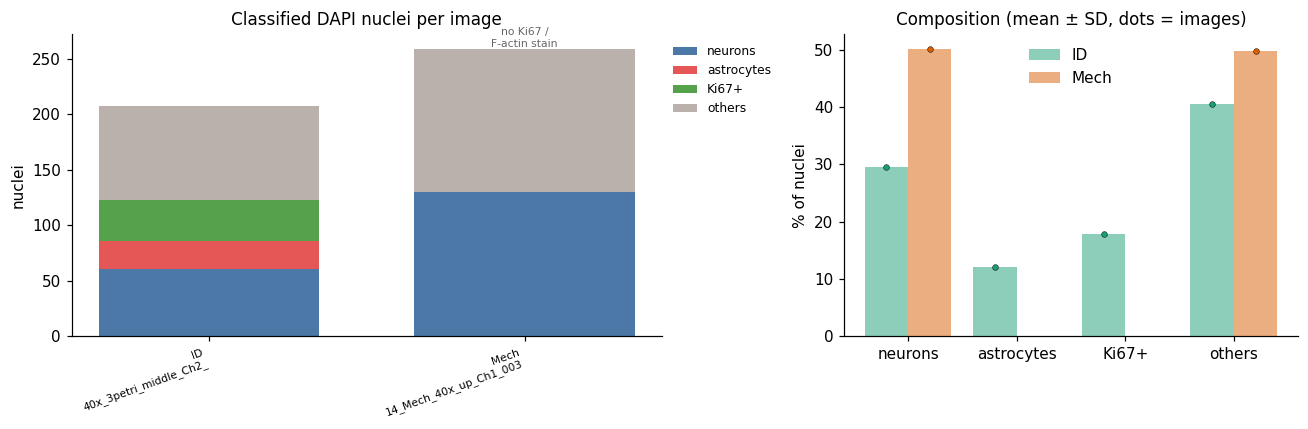

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.3, 1]})
cats = [('prop_neurons', 'neurons', '#4c78a8'), ('prop_astrocytes', 'astrocytes', '#e45756'), ('ki67_pos', 'Ki67+', '#54a24b'), ('others', 'others', '#bab0ac')]
ax = axs[0]
order = df_img.sort_values('group').index
bottom = np.zeros(len(order))
for c, lab, col in cats:
    v = df_img.loc[order, c].astype(float).fillna(0).values
    ax.bar(range(len(order)), v, bottom=bottom, color=col, label=lab, width=0.7)
    bottom += v
for i, im in enumerate(order):
    if pd.isna(df_img.loc[im, 'ki67_pos']):
        ax.text(i, bottom[i], 'no Ki67 /\nF-actin stain', ha='center', va='bottom', fontsize=7, color='0.4')
ax.set_xticks(range(len(order)), [f"{df_img.loc[i, 'group']}\n{i[-22:]}" for i in order], fontsize=7, rotation=20, ha='right')
ax.set_ylabel('nuclei'); ax.set_title('Classified DAPI nuclei per image'); ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax = axs[1]
frac = df_img[[c for c, _, _ in cats]].div(df_img['nuclei'], axis=0) * 100
w = 0.8 / len(group_order())
for j, g in enumerate(group_order()):
    sub = frac[df_img['group'] == g]
    m = sub.mean()
    ax.bar(np.arange(len(cats)) + (j - (len(group_order()) - 1) / 2) * w, m.values, w, color=GROUPS[g], alpha=0.5, label=g,
           yerr=sub.std(ddof=1).values if len(sub) > 1 else None, capsize=3)
    for k, (c, _, _) in enumerate(cats):
        ax.scatter(np.full(len(sub), k + (j - (len(group_order()) - 1) / 2) * w), sub[c], color=GROUPS[g], s=14, edgecolor='k', lw=0.3, zorder=3)
ax.set_xticks(range(len(cats)), [l for _, l, _ in cats]); ax.set_ylabel('% of nuclei'); ax.set_title('Composition (mean ± SD, dots = images)')
ax.legend(frameon=False)
save(fig, 'fig1_soma_composition')

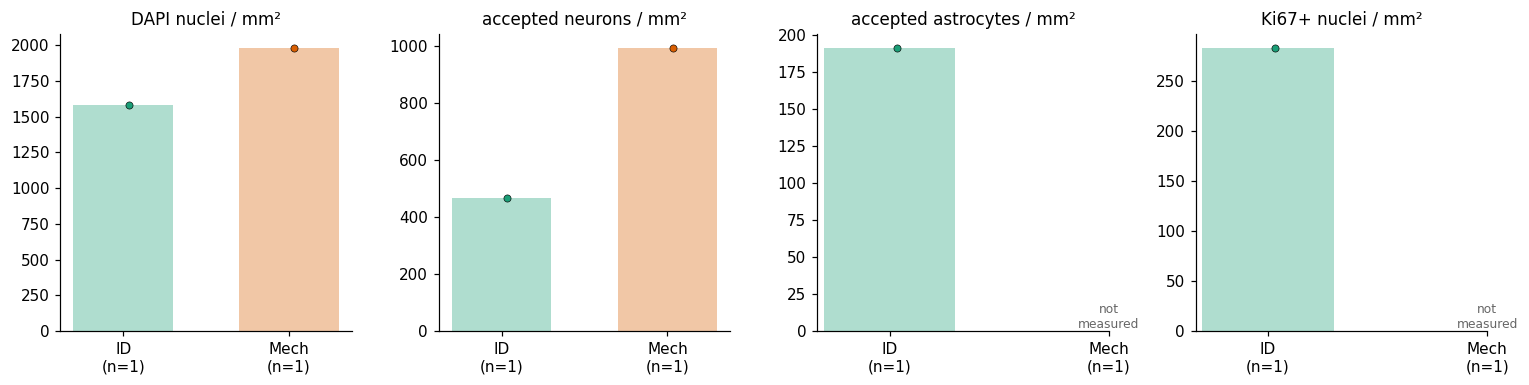

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
per_image_plot(axs[0], 'nuclei_per_mm2', 'DAPI nuclei / mm²')
per_image_plot(axs[1], 'accepted_neurons_per_mm2', 'accepted neurons / mm²')
per_image_plot(axs[2], 'accepted_astrocytes_per_mm2', 'accepted astrocytes / mm²')
per_image_plot(axs[3], 'ki67_pos_per_mm2', 'Ki67+ nuclei / mm²')
save(fig, 'fig2_soma_densities')

## 2. Reconstruction: segmentation and neuron volumes
*Segmentation* = voxels kept by the k-means segmentation; *unassigned* = segmented voxels not reached from any accepted soma by the
watershed (neurites of non-accepted cells, isolated pieces). *Neurite volume* = neuron volume farther than 10 µm from its soma centre.

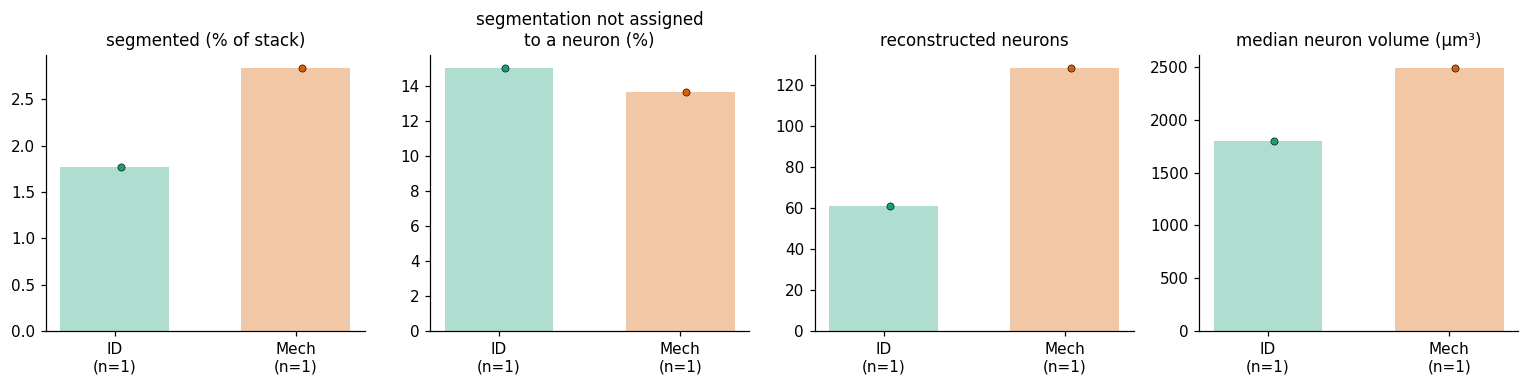

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
df_img['seg_percent'] = df_img['seg_fraction'] * 100
df_img['unassigned_percent'] = df_img['unassigned_fraction'] * 100
per_image_plot(axs[0], 'seg_percent', 'segmented (% of stack)', fmt='{:.1f}')
per_image_plot(axs[1], 'unassigned_percent', 'segmentation not assigned\nto a neuron (%)')
per_image_plot(axs[2], 'neurons', 'reconstructed neurons')
per_image_plot(axs[3], 'median_volume_um3', 'median neuron volume (µm³)')
save(fig, 'fig3_segmentation')

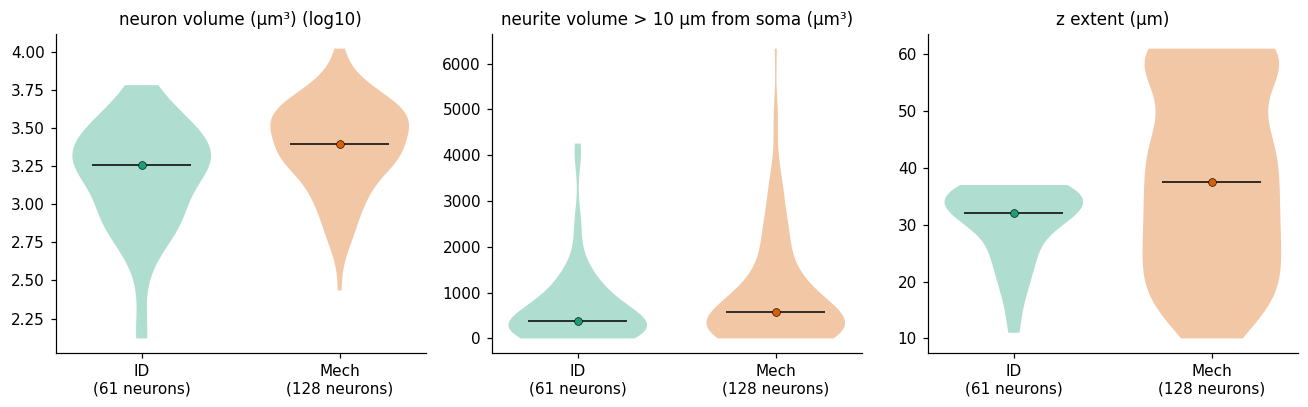

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
per_neuron_plot(axs[0], 'volume_um3', 'neuron volume (µm³)', log=True)
per_neuron_plot(axs[1], 'neurite_volume_um3', f'neurite volume > {FAR_FROM_SOMA_UM:g} µm from soma (µm³)')
per_neuron_plot(axs[2], 'z_extent_um', 'z extent (µm)')
save(fig, 'fig4_neuron_volumes')

## 3. Morphology (SWC skeletons)
Total length (stems from the soma surface), branch points, tips, primary neurites (stems), maximal reach (straight distance soma → farthest point),
mean section length (between branch points / tips). Sholl: number of skeleton crossings of spheres centred on the soma.

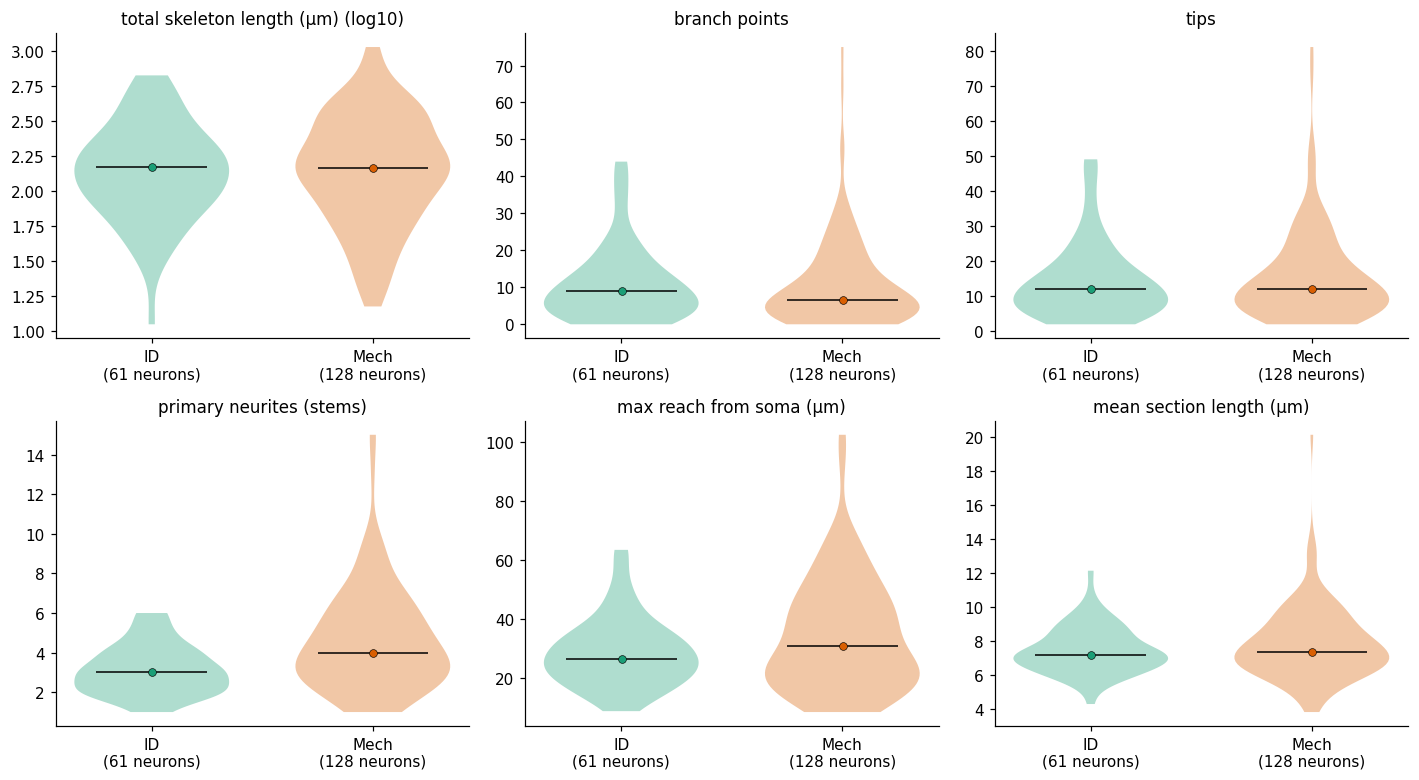

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (c, l, lg) in zip(axs.ravel(), [('length_um', 'total skeleton length (µm)', True), ('branch_points', 'branch points', False),
                                         ('tips', 'tips', False), ('stems', 'primary neurites (stems)', False),
                                         ('max_reach_um', 'max reach from soma (µm)', False), ('mean_section_um', 'mean section length (µm)', False)]):
    per_neuron_plot(ax, c, l, log=lg)
save(fig, 'fig5_morphology')

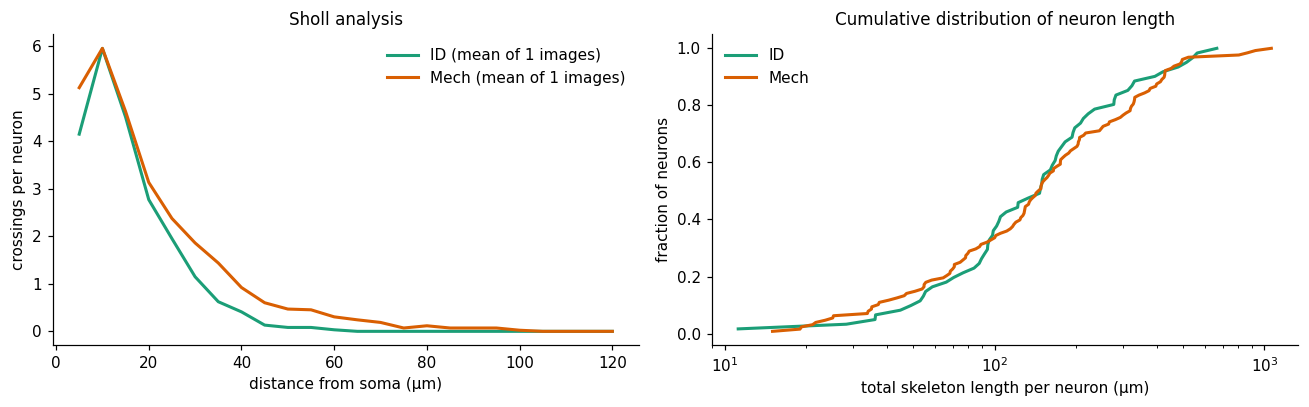

In [11]:
radii = np.arange(SHOLL_STEP_UM, SHOLL_MAX_UM + 1e-9, SHOLL_STEP_UM)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for g in group_order():
    sub = df_neu[(df_neu['group'] == g) & df_neu['sholl'].notna()]
    per_image = np.array([np.mean(np.stack(s['sholl'].values), axis=0) for _, s in sub.groupby('image')])
    m = per_image.mean(0)
    axs[0].plot(radii, m, color=GROUPS[g], lw=2, label=f'{g} (mean of {len(per_image)} images)')
    if len(per_image) > 1:
        sem = per_image.std(0, ddof=1) / np.sqrt(len(per_image))
        axs[0].fill_between(radii, m - sem, m + sem, color=GROUPS[g], alpha=0.25)
    for row in per_image:
        axs[0].plot(radii, row, color=GROUPS[g], lw=0.6, alpha=0.5)
    # cumulative distribution of total length
    L = np.sort(sub['length_um'].values)
    axs[1].plot(L, np.arange(1, len(L) + 1) / len(L), color=GROUPS[g], lw=2, label=g)
axs[0].set_xlabel('distance from soma (µm)'); axs[0].set_ylabel('crossings per neuron'); axs[0].set_title('Sholl analysis'); axs[0].legend(frameon=False)
axs[1].set_xscale('log'); axs[1].set_xlabel('total skeleton length per neuron (µm)'); axs[1].set_ylabel('fraction of neurons')
axs[1].set_title('Cumulative distribution of neuron length'); axs[1].legend(frameon=False)
save(fig, 'fig6_sholl_length_cdf')

## 4. Summary table (one value per image, mean ± SD per group)

In [12]:
cols = {'nuclei_per_mm2': 'DAPI nuclei / mm²', 'accepted_neurons_per_mm2': 'neurons / mm²', 'accepted_astrocytes_per_mm2': 'astrocytes / mm²',
        'ki67_pos_per_mm2': 'Ki67+ / mm²', 'seg_percent': 'segmented %', 'unassigned_percent': 'unassigned %',
        'median_volume_um3': 'neuron volume µm³ (median)', 'median_neurite_volume_um3': 'neurite volume µm³ (median)',
        'median_length_um': 'skeleton length µm (median)', 'median_branch_points': 'branch points (median)', 'median_tips': 'tips (median)',
        'median_stems': 'stems (median)', 'median_reach_um': 'reach µm (median)', 'median_section_um': 'section length µm (median)'}
rows = {}
for c, l in cols.items():
    r = {}
    for g in group_order():
        v = df_img.loc[df_img['group'] == g, c].astype(float).dropna()
        r[g] = 'not measured' if len(v) == 0 else (f'{v.mean():.3g}' if len(v) == 1 else f'{v.mean():.3g} ± {v.std(ddof=1):.2g}')
    p = group_test(c)
    r['Mann-Whitney p'] = '' if p is None else f'{p:.3g}'
    rows[l] = r
summary = pd.DataFrame(rows).T
summary.to_csv(os.path.join(OUT, 'summary_by_group.csv'))
df_img.drop(columns=['folder'], errors='ignore').to_csv(os.path.join(OUT, 'per_image.csv'))
df_neu.drop(columns=['sholl']).to_csv(os.path.join(OUT, 'per_neuron.csv'), index=False)
summary

,ID,Mech,Mann-Whitney p
DAPI nuclei / mm²,1.58e+03,1.98e+03,
neurons / mm²,466,994,
astrocytes / mm²,191,not measured,
Ki67+ / mm²,283,not measured,
segmented %,1.77,2.84,
unassigned %,15,13.7,
neuron volume µm³ (median),1.81e+03,2.49e+03,
neurite volume µm³ (median),372,570,
skeleton length µm (median),148,147,
branch points (median),9,6.5,
